# End-to-end: regression

This notebook runs one regression job from the question to the report, on hourly bike rentals in Washington, D.C. It follows the same steps as every end-to-end notebook of the course, so you can compare the kinds of problems side by side.

*Session 6, end-to-end notebook. Course material, licence CC BY 4.0.*

## 1 The problem

A bike-sharing company moves bikes between its stations by van. The operations planner asks: **how many bikes will people rent in a given hour**, given the time, the day and the weather? With too few bikes at a station, customers walk away; with too many, the vans drive for nothing.

A fixed guess such as "the average hour" ignores rush hours, weekends and rain. A model can learn from two years of records how demand changes with these inputs. The answer is a number, so this is a **regression** problem.

## 2 Load the data

We import the libraries that every step uses. Each later step imports the scikit-learn parts it needs where it uses them.

In [1]:
# matplotlib draws the figures, pandas holds tables (DataFrames)
import matplotlib.pyplot as plt
import pandas as pd
# fetch_openml downloads a data set from the OpenML website
from sklearn.datasets import fetch_openml

The Bike Sharing Demand data (Capital Bikeshare, Washington, D.C., 2011 and 2012) has one row per hour. `fetch_openml(data_id=42712, as_frame=True)` reads it from OpenML as a DataFrame. The first call downloads about 1 MB and keeps a copy in `~/scikit_learn_data`, so later calls work offline.

In [2]:
# Load the bike data as a DataFrame; .frame keeps features and target in one table
# try/except: if the line under try fails, Python runs the except part instead of crashing
try:
    bikes = fetch_openml(data_id=42712, as_frame=True).frame
# Without internet and without a saved copy, stop with a clear message
except Exception as error:
    raise RuntimeError("The bike data are not cached yet: run this cell once with internet access.") from error

# shape is (number of rows, number of columns)
print(bikes.shape)

(17379, 13)


**What is in the data?** One row is one hour of one day in 2011 or 2012. It holds the calendar, the weather in that hour and the number of bikes rented. The notebook uses all 13 columns; the source also splits `count` into casual and registered users, but this version of the data does not contain that split. Meanings and units follow the OpenML description of the data.

| Column | Meaning | Values or unit |
|---|---|---|
| `season` | season (label from the source, shifted: see the note below) | `spring`, `summer`, `fall`, `winter` |
| `year` | year | 0 = 2011, 1 = 2012 |
| `month` | month | 1 (January) to 12 (December) |
| `hour` | hour of the day | 0 to 23 |
| `holiday` | the day is a public holiday in Washington, D.C. | `True` or `False` |
| `weekday` | day of the week | 0 = Sunday to 6 = Saturday (1 January 2011, a Saturday, has 6) |
| `workingday` | the day is neither a weekend day nor a holiday | `True` or `False` |
| `weather` | the weather in that hour | `clear`: clear or a few clouds; `misty`: mist or clouds; `rain`: light rain or light snow, sometimes with thunder; `heavy_rain`: heavy rain, ice pellets, thunderstorm, or snow and fog (only 3 hours) |
| `temp` | air temperature | degrees Celsius, 0.8 to 41 |
| `feel_temp` | felt temperature (how warm or cold it feels) | degrees Celsius, 0 to 50 |
| `humidity` | relative humidity of the air | a share from 0 to 1 |
| `windspeed` | wind speed | 0 to 57; the source gives no unit |
| `count` | **the target**: the number of bikes rented in that hour | 1 to 977 bikes |

**Careful with `season`: the labels are shifted by one season.** `spring` holds late December to mid-March (really winter), `summer` late March to late June (really spring), and so on to `winter`, which holds late September to late December (really autumn). Why? Nobody can say for certain, because the authors of the data never explained it; most likely it is a mistake in their documentation, not something done on purpose. The original data stores the season as a code from 1 to 4 that starts at the winter solstice (21 December), but its description names code 1 "spring". Kaggle and OpenML copied that description, so the wrong names ended up in the data we load. For the models this does not matter: they only need four different groups. It matters only when you read a plot or a finding: few rentals in `spring` means few rentals in January and February.

## 3 Look at the data

`head()` shows the first rows of the whole table.

In [3]:
# Show the first five rows
bikes.head()

,season,year,month,hour,holiday,weekday,workingday,weather,temp,feel_temp,humidity,windspeed,count
0,spring,0,1,0,False,6,False,clear,9.84,14.395,0.81,0.0,16
1,spring,0,1,1,False,6,False,clear,9.02,13.635,0.80,0.0,40
2,spring,0,1,2,False,6,False,clear,9.02,13.635,0.80,0.0,32
3,spring,0,1,3,False,6,False,clear,9.84,14.395,0.75,0.0,13
4,spring,0,1,4,False,6,False,clear,9.84,14.395,0.75,0.0,1


`describe()` summarises the target: its mean, spread and range in bikes per hour.

In [4]:
# Mean, standard deviation, minimum, quartiles and maximum of the target; round(1): one decimal
bikes["count"].describe().round(1)

count    17379.0
mean       189.5
std        181.4
min          1.0
25%         40.0
50%        142.0
75%        281.0
max        977.0
Name: count, dtype: float64

The hour of the day matters most. We average the rentals for every pair of hour and kind of day:

- `groupby(["hour", "workingday"])["count"].mean()` returns a Series with one value per pair. Its row label has **two levels**, `hour` and `workingday` (a **MultiIndex**): each label is a pair such as `(8, True)`.
- `observed=True` keeps only the pairs that occur in the data. `workingday` is a pandas `category` column, and without it pandas would also list category combinations with no rows (and warn about it).
- `reset_index()` turns the two levels of the label back into ordinary columns. The result is a plain table with three columns, `hour`, `workingday` and `count`, one row per pair: 24 hours × 2 kinds of day = 48 rows.

In [5]:
# Average rentals for every (hour, kind of day) pair; observed=True: only pairs that occur in the data
# round(1): one decimal; reset_index() turns the two-level row label (hour, workingday) back into two ordinary columns
rentals_by_hour = bikes.groupby(["hour", "workingday"], observed=True)["count"].mean().round(1).reset_index()
# The whole table: 48 rows, one per hour and kind of day; count is now the average bikes rented
rentals_by_hour

,hour,workingday,count
0,0,False,90.8
1,0,True,36.8
2,1,False,69.5
3,1,True,16.6
4,2,False,53.2
5,2,True,8.7
6,3,False,25.8
7,3,True,4.9
8,4,False,8.3
9,4,True,5.4


24 working-day hours, 24 hours of days off


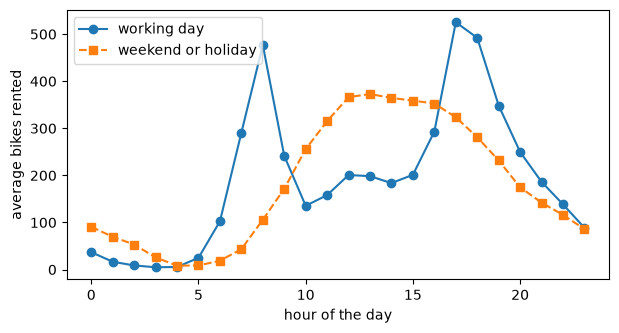

In [6]:
# Split the table into the two kinds of day (workingday holds the text "True" or "False")
working_days = rentals_by_hour[rentals_by_hour["workingday"] == "True"]
days_off = rentals_by_hour[rentals_by_hour["workingday"] == "False"]
print(len(working_days), "working-day hours,", len(days_off), "hours of days off")

# ax.plot draws a line through the points by default (a line chart); marker= adds a dot at each hour
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(working_days["hour"], working_days["count"], marker="o", label="working day")
ax.plot(days_off["hour"], days_off["count"], marker="s", linestyle="--", label="weekend or holiday")
ax.set_xlabel("hour of the day")
ax.set_ylabel("average bikes rented")
ax.legend()
plt.show()

**What do you see?** On working days, demand has two peaks, at 8 in the morning and at 5 to 6 in the evening: people ride to work and back. On other days there is one broad peak from late morning to the afternoon. The effect of the hour depends on the kind of day, which a model has to capture.

## 4 Split the data

We hold back a fifth of the hours as the **test set** and use it once, at the end. `train_test_split` shuffles the rows first; `random_state=0` makes the split the same every time. `X` holds the features and `y` the target.

In [7]:
from sklearn.model_selection import train_test_split

# X: the features (every column except the target); y: the target, bikes rented per hour
X = bikes.drop(columns="count")
y = bikes["count"]
# Keep 20% of the hours as the test set; random_state=0 gives the same split every time
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)
print(len(X_train), "hours (rows) in the training set,", len(X_test), "hours (rows) in the test set")

13903 hours (rows) in the training set, 3476 hours (rows) in the test set


## 5 Process the data

The columns are of two kinds, so a `ColumnTransformer` treats each kind with its own step:

- **Numbers** (`temp`, `feel_temp`, `humidity`, `windspeed`, `year`) are on different scales. `StandardScaler` gives each a mean of 0 and a standard deviation of 1, so the penalty of ridge regression in step 6 treats them alike.
- **Calendar and weather categories** (`hour`, `weekday`, `month`, `season`, `holiday`, `workingday`, `weather`). For a linear model, hour 16 is not "twice hour 8". `OneHotEncoder` gives each hour, weekday and month its own 0/1 column, so each gets its own coefficient.

The transformer learns the means and the categories from the training set only, when it is fitted.

In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Which columns are numbers and which are categories: each kind gets its own processing
numeric_columns = ["temp", "feel_temp", "humidity", "windspeed", "year"]
category_columns = ["hour", "weekday", "month", "season", "holiday", "workingday", "weather"]

# A ColumnTransformer applies one step per group of columns and puts the results side by side.
# Each step is a triple (name, transformer, columns):
#   name: any label you choose, used to find the step later (e.g. "numbers")
#   transformer: what to do with these columns (e.g. StandardScaler())
#   columns: the list of column names the step works on
linear_preprocessing = ColumnTransformer([
    # StandardScaler gives each number a mean of 0 and a standard deviation of 1
    ("numbers", StandardScaler(), numeric_columns),
    # OneHotEncoder turns each category value into its own 0/1 column.
    # handle_unknown="ignore": a value never seen in training (e.g. heavy_rain, which has only 3 hours,
    # could all land in the test set with another split) becomes all zeros instead of stopping with an error
    ("categories", OneHotEncoder(handle_unknown="ignore"), category_columns),
])
# fit_transform learns the means and the categories from the training set and returns a NEW array;
# it does not work in place: X_train itself stays unchanged. We print only the array's shape (rows, columns)
print(linear_preprocessing.fit_transform(X_train).shape)

(13903, 60)


The 12 columns become 60: the 5 numbers plus one 0/1 column per category value, that is 24 hours + 7 weekdays + 12 months + 4 seasons + 2 (`holiday`) + 2 (`workingday`) + 4 kinds of weather = 55. Trees need none of this: they split on thresholds, so scale does not matter, and `HistGradientBoostingRegressor(categorical_features="from_dtype")` treats the pandas `category` columns (`season`, `holiday`, `workingday`, `weather`) as categories by itself. `hour`, `weekday` and `month` are stored as whole numbers, so the trees treat them as numbers and split them at thresholds such as "hour ≤ 7".

## 6 Run the pipeline

We start with the simplest model, score it, and then improve it one step at a time: a linear regression, the same model tuned with a grid search, and then a more flexible model. The five decisions of the three models:

| Decision | Linear regression | Ridge regression | Gradient boosting |
|---|---|---|---|
| Data | the training set (80% of the rows, one row per hour): features X = the calendar and weather columns, target y = the bikes rented | the same | the same |
| Model | a weighted sum of the 60 processed columns | the same | a sum of many small regression trees |
| Loss function | squared error | squared error plus an L2 penalty of strength `alpha` | squared error |
| Optimizer | a formula (least squares, solved exactly) | a formula (a linear system solved exactly) | gradient boosting: each new tree fits the remaining errors; split points from histograms |
| Evaluation | MAE, RMSE and R² on the test set; a plot of predicted against true rentals | the same; `GridSearchCV` chooses `alpha` | the same; `GridSearchCV` chooses the tree settings |

Every model in 6.1 to 6.3 is scored in the same way, with three measures from `sklearn.metrics`:

- **MAE** (`mean_absolute_error`): the average miss, in bikes per hour.
- **RMSE** (`root_mean_squared_error`): the square root of the average squared miss, also in bikes per hour. Large misses count more than in the MAE.
- **R²** (`r2_score`): the share of the variation in rentals that the model explains. 0 means no better than the average, 1 means perfect predictions.

Each section then plots the predicted rentals against the true rentals of the test hours. Points on the dashed line are perfect predictions. The scores go into a dictionary per model (`linear_scores`, `ridge_scores`, `boosting_scores`), from which step 7 builds its table.

### 6.1 Linear regression

`LinearRegression` learns one weight per processed column and predicts their weighted sum. A `Pipeline` chains the preprocessing of step 5 and the model, so `fit` learns both from the training set, and `predict` applies both to new rows.

linear regression: MAE 76.1, RMSE 102.3, R² 0.69


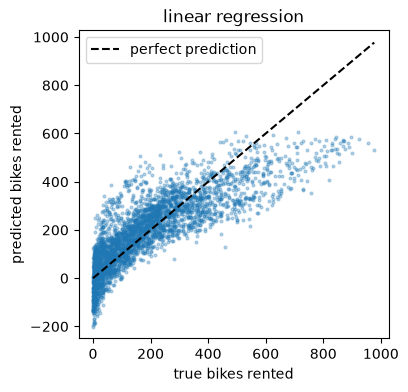

In [9]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.pipeline import Pipeline

# A Pipeline runs its steps in order: first the preprocessing of step 5, then the model;
# each step is a pair (name, step), and the name is ours to choose
linear_pipeline = Pipeline([("preprocessing", linear_preprocessing), ("linear", LinearRegression())])
# fit learns the preprocessing and the weights from the training set
linear_pipeline.fit(X_train, y_train)
# Predict the bikes rented for every test hour; y_predicted_linear: the predicted y of the linear model
y_predicted_linear = linear_pipeline.predict(X_test)
# Each metric compares the true values with the predictions; step 7 builds its table from this dictionary
linear_scores = {
    "model": "linear regression",
    "MAE": mean_absolute_error(y_test, y_predicted_linear),
    "RMSE": root_mean_squared_error(y_test, y_predicted_linear),
    "R²": r2_score(y_test, y_predicted_linear),
}
# f-string: {value:.1f} prints the value with one decimal, {value:.2f} with two
print(f"linear regression: MAE {linear_scores['MAE']:.1f}, RMSE {linear_scores['RMSE']:.1f}, R² {linear_scores['R²']:.2f}")

# One point per test hour: true value on the x-axis, prediction on the y-axis
# largest_count: the most bikes rented in any test hour, the end of the dashed line
largest_count = y_test.max()
fig, ax = plt.subplots(figsize=(4, 4))
# s=4: small points; alpha=0.3: see-through, so dense regions look darker
ax.scatter(y_test, y_predicted_linear, s=4, alpha=0.3)
# The dashed diagonal: points on it are perfect predictions (predicted = true).
# ax.plot(x_values, y_values) takes a list of x-values, then a list of y-values, and joins the points with a line:
# ax.plot([0, largest_count], [0, largest_count], ...)
#          ^ x-values          ^ y-values
# 1st point: x = 0, y = 0                         -> (0, 0)
# 2nd point: x = largest_count, y = largest_count -> (largest_count, largest_count)
ax.plot([0, largest_count], [0, largest_count], linestyle="--", color="black", label="perfect prediction")
# The same axis limits in 6.1 to 6.3, so the plots can be compared;
# the y-axis starts at -250 because the linear models predict some counts below 0
ax.set_xlim(-50, largest_count + 50)
ax.set_ylim(-250, largest_count + 50)
ax.set_xlabel("true bikes rented")
ax.set_ylabel("predicted bikes rented")
ax.set_title("linear regression")
ax.legend(loc="upper left")
plt.show()

**What do you see?** The linear model misses by 76.1 bikes per hour on average and explains 69% of the variation (R² 0.69). The plot shows two patterns. In busy hours above about 600 bikes, all predictions stay too low. In quiet hours, some predictions are below 0, which is impossible for a count.

### 6.2 Tune the linear model with a grid search

**Regularisation** keeps a model from fitting noise in the training hours: the loss gets an extra term that grows with the size of the weights, so a large weight must earn its place. Ridge regression is linear regression with this penalty (the L2 penalty, the sum of the squared weights). Its strength `alpha` is a **hyperparameter**: a setting we choose, which the model does not learn from the data. A larger `alpha` is a stronger penalty and smaller weights; `alpha` near 0 is plain linear regression. Too small risks overfitting, too large underfits, so we try several values. `GridSearchCV` tries each value in a list and keeps the best one. It scores each value on parts of the training set only, so the test set stays unseen until we score the winner.

- `{"ridge__alpha": [0.1, 1, 10, 100]}` is the grid: `ridge__alpha` means the argument `alpha` of the step named `ridge`.
- `scoring="neg_mean_absolute_error"` chooses by MAE. It is negated because scikit-learn always maximizes a score.
- After the search, `best_params_` is the chosen value and `best_estimator_` is the pipeline refitted with it on the whole training set.

chosen: {'ridge__alpha': 10}
ridge regression, tuned: MAE 76.0, RMSE 102.3, R² 0.69


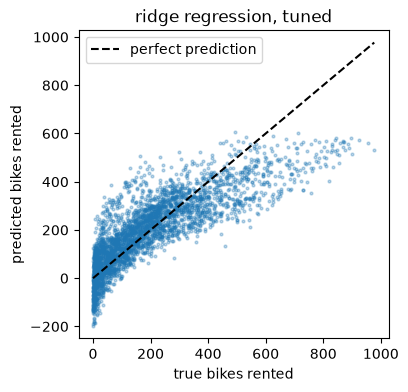

In [10]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV

# The same pipeline, with Ridge (linear regression with a penalty) as the model
ridge_pipeline = Pipeline([("preprocessing", linear_preprocessing), ("ridge", Ridge())])
# Try four penalty strengths and keep the one with the lowest MAE. By default GridSearchCV splits
# the training set into 5 parts, fits on 4 and scores on the 5th, for each part in turn
ridge_search = GridSearchCV(ridge_pipeline, {"ridge__alpha": [0.1, 1, 10, 100]},
                            scoring="neg_mean_absolute_error")
# fit runs the whole search, then refits the best pipeline on all training hours
ridge_search.fit(X_train, y_train)
print("chosen:", ridge_search.best_params_)
# best_estimator_ is the refitted best pipeline; only now do we use the test set
# Predict the bikes rented for every test hour
y_predicted_ridge = ridge_search.best_estimator_.predict(X_test)
# Each metric compares the true values with the predictions; step 7 builds its table from this dictionary
ridge_scores = {
    "model": "ridge regression, tuned",
    "MAE": mean_absolute_error(y_test, y_predicted_ridge),
    "RMSE": root_mean_squared_error(y_test, y_predicted_ridge),
    "R²": r2_score(y_test, y_predicted_ridge),
}
# f-string: {value:.1f} prints the value with one decimal, {value:.2f} with two
print(f"ridge regression, tuned: MAE {ridge_scores['MAE']:.1f}, RMSE {ridge_scores['RMSE']:.1f}, R² {ridge_scores['R²']:.2f}")

# One point per test hour: true value on the x-axis, prediction on the y-axis
# largest_count: the most bikes rented in any test hour, the end of the dashed line
largest_count = y_test.max()
fig, ax = plt.subplots(figsize=(4, 4))
# s=4: small points; alpha=0.3: see-through, so dense regions look darker
ax.scatter(y_test, y_predicted_ridge, s=4, alpha=0.3)
# The dashed diagonal: points on it are perfect predictions
ax.plot([0, largest_count], [0, largest_count], linestyle="--", color="black", label="perfect prediction")
# The same axis limits in 6.1 to 6.3, so the plots can be compared;
# the y-axis starts at -250 because the linear models predict some counts below 0
ax.set_xlim(-50, largest_count + 50)
ax.set_ylim(-250, largest_count + 50)
ax.set_xlabel("true bikes rented")
ax.set_ylabel("predicted bikes rented")
ax.set_title("ridge regression, tuned")
ax.legend(loc="upper left")
plt.show()

**What do you see?** The grid search chose `alpha = 10`, but the scores barely move: MAE 76.0 instead of 76.1, and the plot looks the same. With about 14,000 training hours and 60 columns, the weights are already stable, so a penalty has little to correct. The limit is the model, not its setting. A weighted sum gives each hour one weight for every kind of day, but step 3 showed that the hour matters differently on working days and on weekends.

### 6.3 A more flexible model: gradient boosting

Gradient boosting adds many small regression trees. A tree can split first on the kind of day and then on the hour, so it can learn the two daily patterns of step 3. Trees need no scaling and no one-hot columns, so this pipeline has the model step only.

**What does "Hist" mean?** To grow a tree, the model must find good split points such as "temp ≤ 18.5". A plain tree tries every distinct value of every column, which is slow with about 14,000 training hours. `HistGradientBoostingRegressor` first sorts each number column into at most 256 bins, like the bars of a **histogram**, and then tries only the bin edges as split points. The trees are almost as good, and fitting is much faster. The bins are learned from the training set when `fit` runs.

**What does `categorical_features="from_dtype"` do?** It tells the model to look at the pandas type (`dtype`) of each column of `X_train`:

- a column of type `category` (`season`, `holiday`, `workingday`, `weather`) is treated as a set of labels. A split puts some labels on one side and the rest on the other, for example `{rain, heavy_rain}` against `{clear, misty}`. The labels have no order, so "rain > clear" never appears;
- every other column (`hour`, `month`, `weekday` and the weather numbers) is treated as a number and split at a threshold, such as "hour ≤ 7".

During `fit`, the model notes which labels each category column has in the training set. At `predict`, a label it never saw is treated like a missing value. Nothing in the data is changed: the model reads the types, so the pipeline needs no preprocessing step.

The grid tries two learning rates (how much each new tree corrects) and two tree sizes (`max_leaf_nodes`, the most leaves one tree may have), four settings in all. Both are hyperparameters, and both are a form of regularisation: a small learning rate and small trees make each step cautious, so the model fits the training hours less tightly.

chosen: {'boosting__learning_rate': 0.1, 'boosting__max_leaf_nodes': 31}
gradient boosting, tuned: MAE 26.8, RMSE 43.5, R² 0.94


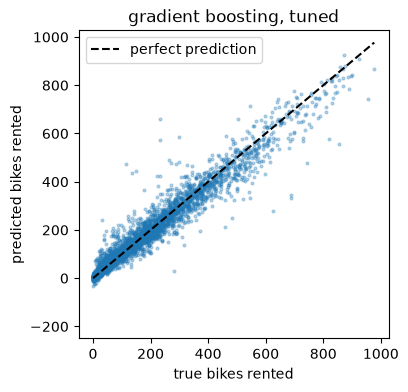

In [11]:
from sklearn.ensemble import HistGradientBoostingRegressor

# "Hist": each number column is sorted into at most 256 bins, and only the bin edges are tried as split points.
# Trees need no scaling or one-hot columns, so the pipeline has the model step only.
# categorical_features="from_dtype": columns of pandas type category (season, holiday, workingday, weather)
# are split into groups of labels; all other columns are split at a threshold such as "hour <= 7".
# random_state=0 fixes the random choices inside the model, so every run gives the same result
boosting_pipeline = Pipeline([
    ("boosting", HistGradientBoostingRegressor(categorical_features="from_dtype", random_state=0)),
])
# 2 learning rates × 2 tree sizes = 4 settings to try; the names are step name + "__" + argument,
# as with ridge__alpha in 6.2
boosting_grid = {"boosting__learning_rate": [0.05, 0.1], "boosting__max_leaf_nodes": [15, 31]}
boosting_search = GridSearchCV(boosting_pipeline, boosting_grid, scoring="neg_mean_absolute_error")
# fit runs the whole search, then refits the best pipeline on the whole training set
boosting_search.fit(X_train, y_train)
print("chosen:", boosting_search.best_params_)
# Predict the bikes rented for every test hour
y_predicted_boosting = boosting_search.best_estimator_.predict(X_test)
# Each metric compares the true values with the predictions; step 7 builds its table from this dictionary
boosting_scores = {
    "model": "gradient boosting, tuned",
    "MAE": mean_absolute_error(y_test, y_predicted_boosting),
    "RMSE": root_mean_squared_error(y_test, y_predicted_boosting),
    "R²": r2_score(y_test, y_predicted_boosting),
}
# f-string: {value:.1f} prints the value with one decimal, {value:.2f} with two
print(f"gradient boosting, tuned: MAE {boosting_scores['MAE']:.1f}, RMSE {boosting_scores['RMSE']:.1f}, R² {boosting_scores['R²']:.2f}")

# One point per test hour: true value on the x-axis, prediction on the y-axis
# largest_count: the most bikes rented in any test hour, the end of the dashed line
largest_count = y_test.max()
fig, ax = plt.subplots(figsize=(4, 4))
# s=4: small points; alpha=0.3: see-through, so dense regions look darker
ax.scatter(y_test, y_predicted_boosting, s=4, alpha=0.3)
# The dashed diagonal: points on it are perfect predictions
ax.plot([0, largest_count], [0, largest_count], linestyle="--", color="black", label="perfect prediction")
# The same axis limits in 6.1 to 6.3, so the plots can be compared;
# the y-axis starts at -250 because the linear models predict some counts below 0
ax.set_xlim(-50, largest_count + 50)
ax.set_ylim(-250, largest_count + 50)
ax.set_xlabel("true bikes rented")
ax.set_ylabel("predicted bikes rented")
ax.set_title("gradient boosting, tuned")
ax.legend(loc="upper left")
plt.show()

**What do you see?** The grid search chose a learning rate of 0.1 and 31 leaves per tree. The MAE falls from 76.0 to 26.8 bikes per hour, and R² rises to 0.94. The points now lie close to the dashed line, also in busy hours, and no prediction is far below 0. The spread grows with demand: in busy hours the misses are larger in bikes, though not much larger as a share of demand.

## 7 Report the results

One table puts the three models side by side, in the order we built them. Then we ask how sure these numbers are.

In [12]:
# One row per model, built from the score dictionaries of 6.1 to 6.3:
# each dictionary becomes a row, its keys become the columns; set_index("model") uses the names as row labels
test_results = pd.DataFrame([linear_scores, ridge_scores, boosting_scores]).set_index("model").round(2)
test_results

,MAE,RMSE,R²
model,,,
linear regression,76.09,102.34,0.69
"ridge regression, tuned",75.99,102.31,0.69
"gradient boosting, tuned",26.82,43.51,0.94


### 7.1 How sure is each score?

The test set is one sample of hours. Another sample of hours would give slightly different scores. A **95% confidence interval** shows how far a score could move for that reason: over many test sets, 95 of 100 such intervals contain the model's true score.

We report the interval of **R²**, the share of the variation in rentals that a model explains, because it is the usual summary of a regression and can be compared across data sets: 0 means no better than the average, 1 means perfect.

R² has no simple formula for its interval, so we use the **bootstrap**. The fitted models stay fixed; only the test rows are drawn again:

1. Draw as many test rows as there are, **with replacement**: some hours appear twice, some not at all.
2. Compute R² on these rows: 1 minus the squared misses of the model divided by the squared distances of the true counts from their mean.
3. Repeat 1,000 times. The middle 95% of the 1,000 values of R², from the 2.5th to the 97.5th percentile, is the interval.

`rng.integers(0, n, size=(1000, n))` draws the row positions of all 1,000 resamples at once, one resample per row of the array.

In [13]:
import numpy as np

# The test predictions of every model, computed once: the bootstrap never refits a model
fitted_models = {
    "linear regression": linear_pipeline,
    "ridge regression, tuned": ridge_search.best_estimator_,
    "gradient boosting, tuned": boosting_search.best_estimator_,
}
y_predicted_by_model = {}
for model_name, model in fitted_models.items():
    y_predicted_by_model[model_name] = model.predict(X_test)

# rng is a random number generator; seed 0 gives the same resamples every run
# 1,000 resamples of the test rows; each row of resampled_rows holds the positions of one resample:
# n_test_rows whole numbers from 0 to n_test_rows - 1, drawn with replacement
rng = np.random.default_rng(0)
n_resamples = 1000
n_test_rows = len(y_test)
resampled_rows = rng.integers(0, n_test_rows, size=(n_resamples, n_test_rows))

# to_numpy() turns y_test into a plain array, so [rows] picks rows by position (0, 1, 2, ...);
# y_test itself keeps the shuffled row labels of the split
true_counts = y_test.to_numpy()
# R² of every model on every resample: true_counts[rows] and y_predicted[rows] pick the same rows
bootstrap_r2 = {}
for model_name, y_predicted in y_predicted_by_model.items():
    bootstrap_r2[model_name] = np.array([r2_score(true_counts[rows], y_predicted[rows])
                                         for rows in resampled_rows])

# The interval: the 2.5th and the 97.5th percentile of the 1,000 values of R²;
# np.percentile returns the two values, which we unpack into lower and upper
interval_rows = []
for model_name, r2_values in bootstrap_r2.items():
    lower, upper = np.percentile(r2_values, [2.5, 97.5])
    interval_rows.append({"model": model_name,
                          "R²": r2_score(true_counts, y_predicted_by_model[model_name]),
                          "95% CI from": lower, "95% CI to": upper})
r2_intervals = pd.DataFrame(interval_rows).set_index("model").round(3)
r2_intervals

,R²,95% CI from,95% CI to
model,,,
linear regression,0.686,0.671,0.701
"ridge regression, tuned",0.686,0.671,0.701
"gradient boosting, tuned",0.943,0.935,0.951


**What do you see?** The two linear models explain 68.6% of the variation, with an interval of 67.1% to 70.1%; their intervals are the same to three decimals. Gradient boosting explains 94.3%, with an interval of 93.5% to 95.1%, far above both. Each R² is uncertain by about ±1.5 points for the linear models and ±0.8 points for gradient boosting. Whether two models really differ is a separate question, and section 7.2 answers it.

### 7.2 Is the next model really better? The interval of the difference

To compare two models, we do not compare their two intervals. Both models are scored on the **same** test hours. When the resample happens to hold many easy hours, both models do well; when it holds many hard hours, both do worse. Most of the width of each interval comes from this shared luck, and it cancels when we subtract one score from the other.

So we compute the **gain** of each step on every resample, with the same rows for both models: the R² of the later model minus the R² of the earlier one. A positive gain means the later model explains more of the variation. The middle 95% of the 1,000 gains is the **95% interval of the difference**:

- the interval lies above 0: the later model is better, by about the amount the interval shows;
- the interval contains 0: on this test set we cannot tell the two models apart.

In [14]:
# Each step of section 6, as (short label, earlier model, later model)
steps = [("linear → ridge", "linear regression", "ridge regression, tuned"),
         ("ridge → boosting", "ridge regression, tuned", "gradient boosting, tuned")]

# One row per step: the gain on the whole test set and its 95% interval
gain_rows = []
for label, earlier, later in steps:
    # The same resampled rows for both models, so every gain compares them on the same hours;
    # subtracting two arrays of 1,000 values of R² gives 1,000 gains, one per resample
    gains = bootstrap_r2[later] - bootstrap_r2[earlier]
    lower, upper = np.percentile(gains, [2.5, 97.5])
    gain_rows.append({"step": label,
                      "gain in R²": (r2_score(true_counts, y_predicted_by_model[later])
                                     - r2_score(true_counts, y_predicted_by_model[earlier])),
                      "95% CI from": lower, "95% CI to": upper})
r2_gains = pd.DataFrame(gain_rows).set_index("step").round(4)
r2_gains

,gain in R²,95% CI from,95% CI to
step,,,
linear → ridge,0.0002,-0.0004,0.0008
ridge → boosting,0.2570,0.2427,0.2717


A histogram of the 1,000 gains of each step shows the same thing as a picture. The dashed line marks a gain of 0, "no difference".

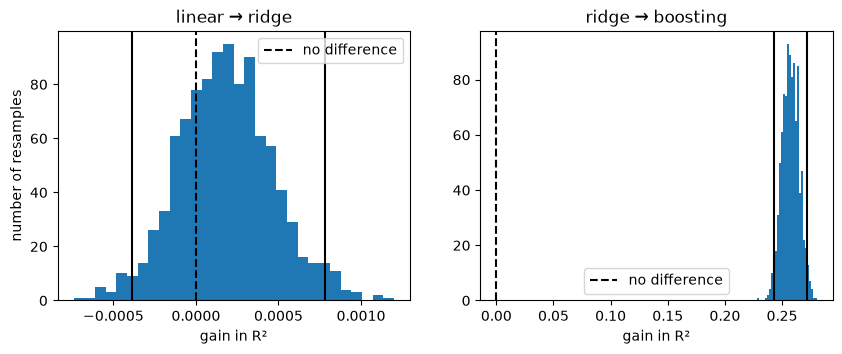

In [15]:
# Two plots side by side: axes holds both, and zip pairs each plot with one step
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, (label, earlier, later) in zip(axes, steps):
    # The 1,000 gains of this step, as in the cell above
    gains = bootstrap_r2[later] - bootstrap_r2[earlier]
    # ax.hist counts how many gains fall into each of 30 equal bins
    ax.hist(gains, bins=30)
    # The 95% interval as two solid lines, the value 0 as a dashed line (axvline: a vertical line at x)
    for bound in np.percentile(gains, [2.5, 97.5]):
        ax.axvline(bound, color="black")
    ax.axvline(0, color="black", linestyle="--", label="no difference")
    ax.set_title(label)
    ax.set_xlabel("gain in R²")
    ax.legend()
# Only the left plot needs the y-axis label
axes[0].set_ylabel("number of resamples")
plt.show()

**What do you see?** Left: tuning the ridge penalty changes R² by 0.0002, with an interval of −0.0004 to 0.0008 that contains 0. On this test set we cannot tell the tuned and the untuned linear model apart: tuning was not worth it.

Right: gradient boosting explains 0.257 more of the variation than tuned ridge regression (95% interval 0.243 to 0.272), far above 0. The separate intervals in 7.1 already showed that it is better; the interval of the difference adds **how much** better, with its range.

For the planner, R² can be turned back into bikes: the MAE of 6.1 to 6.3 says gradient boosting misses 26.8 bikes per hour on average, against 76.0 for tuned ridge regression.

**One assumption to check.** The bootstrap treats every test hour as an independent draw. Hours of the same day share their weather, so they are not fully independent, and the intervals above are somewhat too narrow. Resampling whole days instead would widen them. Here the gain of gradient boosting is so large that wider intervals would not change the conclusion.

### 7.3 Use the model on a new input

Imagine the planner has deployed the chosen model, tuned gradient boosting. Each evening the planner gives it the hours of the next day: one row per hour with the same 12 columns as `X_train`, the calendar and the weather forecast. The model returns one number per row, the bikes it expects to be rented. Here are two new hours: a working Tuesday morning in June with clear weather, and a rainy Sunday afternoon in November.

Two details: the new table must have the same column types as the training table, so `astype(X_train.dtypes.to_dict())` copies them; and `season` uses the shifted labels of the source (10 June is `summer`, 18 November is `winter`).

In [16]:
# Two new hours, one row each, with the same 12 columns as X_train
new_hours = pd.DataFrame({
    "season": ["summer", "winter"],       # the source's labels: 10 June -> summer, 18 November -> winter
    "year": [1, 1],                       # 1 = 2012
    "month": [6, 11],
    "hour": [8, 15],                      # 8 in the morning, 3 in the afternoon
    "holiday": ["False", "False"],
    "weekday": [2, 0],                    # 2 = Tuesday, 0 = Sunday
    "workingday": ["True", "False"],
    "weather": ["clear", "rain"],
    "temp": [24.0, 9.0],                  # degrees Celsius
    "feel_temp": [27.0, 6.0],             # degrees Celsius
    "humidity": [0.55, 0.90],             # share from 0 to 1
    "windspeed": [10.0, 20.0],
})
# Give every column the same type as in the training table (e.g. season becomes a category again)
new_hours = new_hours.astype(X_train.dtypes.to_dict())
# The input, in full
new_hours

,season,year,month,hour,holiday,weekday,workingday,weather,temp,feel_temp,humidity,windspeed
0,summer,1,6,8,False,2,True,clear,24.0,27.0,0.55,10.0
1,winter,1,11,15,False,0,False,rain,9.0,6.0,0.90,20.0


In [17]:
# The chosen model: the tuned gradient boosting pipeline, already fitted in 6.3 (no new fit)
chosen_model = boosting_search.best_estimator_
# predict returns one number per row: the bikes the model expects to be rented in that hour
y_predicted_new = chosen_model.predict(new_hours)
print(y_predicted_new)
# The same numbers next to the input that matters most, in whole bikes
print(f"working Tuesday, 8:00, clear: {y_predicted_new[0]:.0f} bikes expected")
print(f"Sunday, 15:00, rain:          {y_predicted_new[1]:.0f} bikes expected")

[712.68658253 107.66881172]
working Tuesday, 8:00, clear: 713 bikes expected
Sunday, 15:00, rain:          108 bikes expected


**What do you see?** The model expects about 713 bikes on the working Tuesday at 8 in the morning, the morning rush of step 3, and about 108 on the rainy Sunday afternoon. The input is a plain table with the same columns as the training data; the output is one number per row. This is all a deployed model does: the planner sends next day's 24 hours as 24 rows and gets 24 numbers back, one per hour, to plan the vans.

**Finding.** Tuned gradient boosting explains 94.3% of the variation in hourly bike rentals on the test hours (R² 0.943, 95% CI 0.935 to 0.951); on average it misses by 26.8 bikes per hour (MAE). That is 0.257 more of the variation than tuned ridge regression (95% CI of the difference 0.243 to 0.272), while tuning the ridge penalty changed R² by only 0.0002, with an interval that contains 0. One limitation: hours of the same day are not independent, so the intervals are somewhat too narrow, and the split mixes hours of the same days into the training set and the test set; a real forecast of tomorrow would do worse, and the forecasting notebook of Session 12 splits by time instead.

## 8 A recent method

Gradient boosting on trees, as above, is still the strong default for tables like this one. A newer idea is a **tabular foundation model**. TabPFN (Hollmann, Müller, Hutter and colleagues, University of Freiburg and Prior Labs, *Nature*, 2025) is a transformer trained in advance on millions of made-up tables. For a new table it predicts in one forward pass, with the training rows as its input, and it needs no tuning. The 2025 paper reports it ahead of tuned gradient boosting on tables of up to 10,000 training rows.

TabPFN is not installed in the course environment. With it, the model step of the pipeline would read:

```python
from tabpfn import TabPFNRegressor

tabpfn_model = TabPFNRegressor(random_state=0).fit(X_train, y_train)
y_predicted_tabpfn = tabpfn_model.predict(X_test)
```

Compare it with the table above in the same way: the same split and the same scores.

> 📖 **Read more:** [TabPFN paper](https://www.nature.com/articles/s41586-024-08328-6) (Hollmann et al., *Nature* 637, 2025): how the model was trained and where it is better than gradient boosting.